# Term metrics: road users, methods, sensors and observed aspects

Counts how many screened records mention each category, by matching term dictionaries (regular expressions) against **title + abstract + author keywords**. No API, no model: the same input always gives the same numbers.

How to read the results:

- **Mention, not focus.** A record counts for a category if its text contains one of the terms. A paper that mentions YOLO only as a baseline still counts as YOLO.
- **Multi-label.** Methods, sensors and observed aspects can overlap, so their percentages do not sum to 100%. Only the road-user classification is exclusive.
- **Abstract-level.** A method or sensor that the abstract does not name is not counted, so shares are lower bounds.
- **Periods.** 2016–19, 2020–22, 2023–26. 2026 is a partial year; shares within a period are comparable, raw counts are not.

These are exploratory indicators for the panorama section of the paper (write "X% of records mention…", not "use"). Only **specific, named terms** are kept: a precision audit on the corpus showed that generic terms ("real-time", "safety", "flow", "tracking") mostly come from motivation sentences, not from what the study does, so they were removed. What each study actually uses and observes (the RQs) comes from the per-record LLM extraction (notebook 09), not from this notebook.

In [ ]:
import json
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 200)
sns.set(style="whitegrid")
plt.rcParams.update({"font.family": "Times New Roman"})

MATTE_COLORS = {
    'blue': '#4f9dc4', 'red': '#e9785a', 'teal': '#8ed165', 'navy': '#3b3d3f',
    'gold': '#f2d156', 'text': '#333333', 'pink': '#d97eb8', 'purple': '#9478d5',
    'grid': '#dddddd', 'background': '#f7f7f7',
}
PERIOD_COLORS = [MATTE_COLORS['gold'], MATTE_COLORS['blue'], MATTE_COLORS['navy']]

CONFIG = {
    "INPUT_PATH": "../data/04_llm_screened_corpus.json",
    "OUTPUT_CSV": "../data/06_term_metrics.csv",
    "PERIODS": {"2016–19": (2016, 2019), "2020–22": (2020, 2022), "2023–26": (2023, 2026)},
}

## Term dictionaries

Edit here to add, remove or refine terms; every chart below updates. Patterns are lower-case regular expressions (`\b` marks a word boundary). Check the audit cell at the end after any change, to see which records a term actually catches.

In [2]:
DICTIONARIES = {
    "CV methods": {
        "Deep learning / CNN": r"deep learning|neural network|\bcnn\b|convolutional",
        "YOLO (any version)": r"\byolo",
        "R-CNN / SSD / DETR": r"r-cnn|rcnn|\bssd\b|retinanet|\bdetr\b",
        "Transformer / attention": r"transformer|attention mechanism|self-attention",
        # Plain "tracking" removed: it also matched GPS tracking, gaze tracking and generic prose.
        "Multi-object tracking (DeepSORT, ByteTrack, Kalman, MOT)":
            r"deepsort|deep sort|bytetrack|\bsort tracker|multi-object tracking|multiple object tracking|multi-target tracking|kalman",
        "Segmentation": r"segmentation",
        "Pose / skeleton": r"pose estimation|skeleton|openpose|keypoint",
        "Trajectory prediction / LSTM": r"trajectory prediction|trajectory forecasting|lstm",
        "Classical CV (optical flow, HOG, SVM, background subtraction)":
            r"optical flow|background subtraction|\bhog\b|histogram of oriented|\bsvm\b|support vector",
        "LLM / VLM / foundation model":
            r"large language model|\bllms?\b|vision-language|foundation model|\bclip\b|segment anything|\bgpt|multimodal",
    },
    "Sensors and platforms": {
        "Fixed / CCTV / traffic / roadside camera":
            r"cctv|surveillance|traffic camera|roadside|intersection camera|fixed camera|closed-circuit",
        "Drone / UAV": r"drone|\buavs?\b|unmanned aerial|aerial",
        "Vehicle-mounted / dashcam": r"dashcam|dash cam|vehicle-mounted|on-board|onboard|in-vehicle|ego-vehicle|driving recorder",
        "Wearable / bike- or rider-mounted": r"wearable|helmet-mounted|helmet mounted|bicycle-mounted|handlebar|body-worn|head-mounted|bike-mounted|rider-mounted",
        "Smartphone": r"smartphone|mobile phone",
        "Fisheye / 360°": r"fisheye|fish-eye|\b360\b|omnidirectional",
        "Depth / stereo / LiDAR or radar fusion": r"stereo|depth camera|rgb-d|lidar|radar|sensor fusion",
        # "real-time" removed: it is almost always a claim about speed, not a device.
        "Edge / embedded hardware / IoT": r"edge computing|edge device|embedded system|embedded device|jetson|raspberry|\biot\b|internet of things",
    },
    # Only specific application terms. Generic categories (safety, counting/flow, behaviour, speed/trajectory)
    # were removed: they appear in the motivation of almost every abstract. What is observed (SQ3) comes from
    # the LLM extraction.
    "Specific application terms": {
        "Crossing / crosswalk": r"crossing|crosswalk|zebra|jaywalk",
        "Surrogate safety / near-miss / conflict analysis": r"surrogate safety|near-miss|near miss|near-crash|post-encroachment|time-to-collision|\bttc\b|\bpet\b|traffic conflict",
        "Sidewalk / bike lane / shared path": r"sidewalk|bike lane|bicycle lane|cycle lane|cycle track|footpath|walkway|shared-use path|shared path",
        "Helmet use": r"helmet",
        "Signal control": r"signal control|traffic signal|adaptive signal|pedestrian signal",
        "Assistive / visually impaired": r"assistive|navigation aid|visually impaired|\bblind\b",
    },
}

# Road users: one exclusive class per record, checked in this order.
ROAD_USER_TERMS = {
    "pedestrian": r"pedestrian",
    "cyclist": r"cyclist|bicycl|\bbikes?\b|\be-bikes?\b|cycling",
    "micromobility": r"scooter|micromobility|micro-mobility",
}
ROAD_USER_ORDER = ["Pedestrian only", "Cyclist only", "Pedestrian + cyclist",
                   "Scooter / micromobility (any)", "Unspecified"]

## Load data

In [3]:
df = pd.read_json(CONFIG["INPUT_PATH"])
df["year"] = pd.to_numeric(df["publication_date"].astype(str).str[:4], errors="coerce")

def as_text(x):
    return " ".join(x) if isinstance(x, list) else (x or "")

abstract = df["abstract"].fillna("").str.replace(r"\s*(©|Copyright).*$", "", regex=True)
df["_text"] = (df["title"].fillna("") + " . " + abstract + " . "
               + df["author_keywords"].apply(as_text)).str.lower()

df["period"] = None
for name, (a, b) in CONFIG["PERIODS"].items():
    df.loc[df["year"].between(a, b), "period"] = name
PERIODS = list(CONFIG["PERIODS"])

print(f"Loaded {len(df)} records")
print(df["period"].value_counts().reindex(PERIODS).to_string())

Loaded 377 records
period
2016–19     77
2020–22     94
2023–26    206


## Road users

Exclusive classes: a record that mentions a scooter or micromobility is counted there first, whatever else it mentions; otherwise it is pedestrian-only, cyclist-only, or both.

,records,%
road_user,,
Pedestrian only,269,71.4
Cyclist only,49,13.0
Pedestrian + cyclist,42,11.1
Scooter / micromobility (any),16,4.2
Unspecified,1,0.3


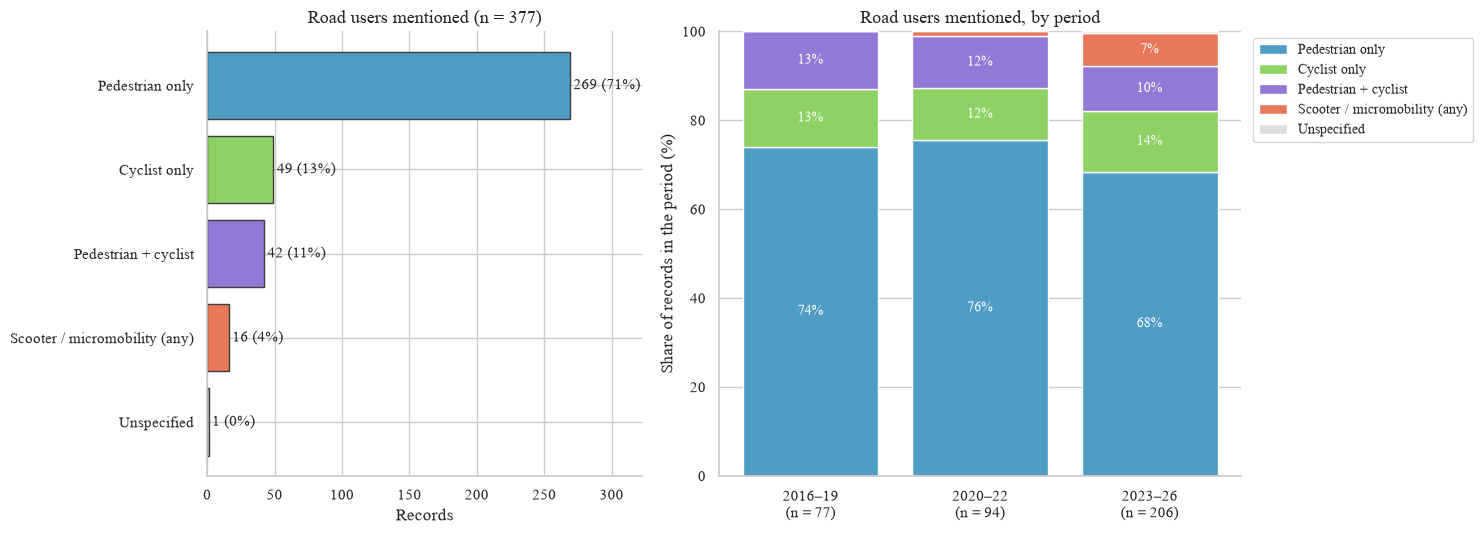

First scooter/micromobility record: 2020


In [4]:
has = {k: df["_text"].str.contains(p, regex=True) for k, p in ROAD_USER_TERMS.items()}
df["road_user"] = np.select(
    [has["micromobility"], has["pedestrian"] & has["cyclist"],
     has["pedestrian"] & ~has["cyclist"], has["cyclist"] & ~has["pedestrian"]],
    ["Scooter / micromobility (any)", "Pedestrian + cyclist", "Pedestrian only", "Cyclist only"],
    default="Unspecified",
)

ru_counts = df["road_user"].value_counts().reindex(ROAD_USER_ORDER, fill_value=0)
ru_counts = ru_counts[ru_counts > 0]
ru_share = ru_counts / len(df) * 100
display(pd.DataFrame({"records": ru_counts, "%": ru_share.round(1)}))

ru_period = (pd.crosstab(df["road_user"], df["period"], normalize="columns") * 100) \
    .reindex(index=ru_counts.index, columns=PERIODS)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.2]})

colors = [MATTE_COLORS[c] for c in ("blue", "teal", "purple", "red", "grid")][:len(ru_counts)]
bars = axes[0].barh(ru_counts.index[::-1], ru_counts.values[::-1], color=colors[::-1],
                    edgecolor=MATTE_COLORS['navy'], linewidth=1)
for bar, n, s in zip(bars, ru_counts.values[::-1], ru_share.values[::-1]):
    axes[0].text(bar.get_width() + ru_counts.max() * 0.01, bar.get_y() + bar.get_height() / 2,
                 f"{n} ({s:.0f}%)", va="center", fontsize=11)
axes[0].set_xlabel("Records")
axes[0].set_title(f"Road users mentioned (n = {len(df)})", fontsize=13)
axes[0].set_xlim(0, ru_counts.max() * 1.2)
axes[0].spines[["top", "right"]].set_visible(False)

bottom = np.zeros(len(PERIODS))
for cat, color in zip(ru_period.index, colors):
    vals = ru_period.loc[cat].fillna(0).to_numpy()
    axes[1].bar(PERIODS, vals, bottom=bottom, label=cat, color=color, edgecolor="white")
    for i, (v, b) in enumerate(zip(vals, bottom)):
        if v >= 5:
            axes[1].text(i, b + v / 2, f"{v:.0f}%", ha="center", va="center", fontsize=10,
                         color="white" if cat != "Unspecified" else MATTE_COLORS['text'])
    bottom += vals
n_per = df["period"].value_counts().reindex(PERIODS)
axes[1].set_xticks(range(len(PERIODS)))
axes[1].set_xticklabels([f"{p}\n(n = {n})" for p, n in n_per.items()])
axes[1].set_ylabel("Share of records in the period (%)")
axes[1].set_title("Road users mentioned, by period", fontsize=13)
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=10)
axes[1].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

first_year = df.loc[df["road_user"] == "Scooter / micromobility (any)", "year"].min()
print(f"First scooter/micromobility record: {first_year:.0f}")

## Methods, sensors and specific application terms

For each dictionary: share of all records that **mention** each category, and the share within each period. Categories are sorted by overall share.

Saved ../data/08_term_metrics.csv


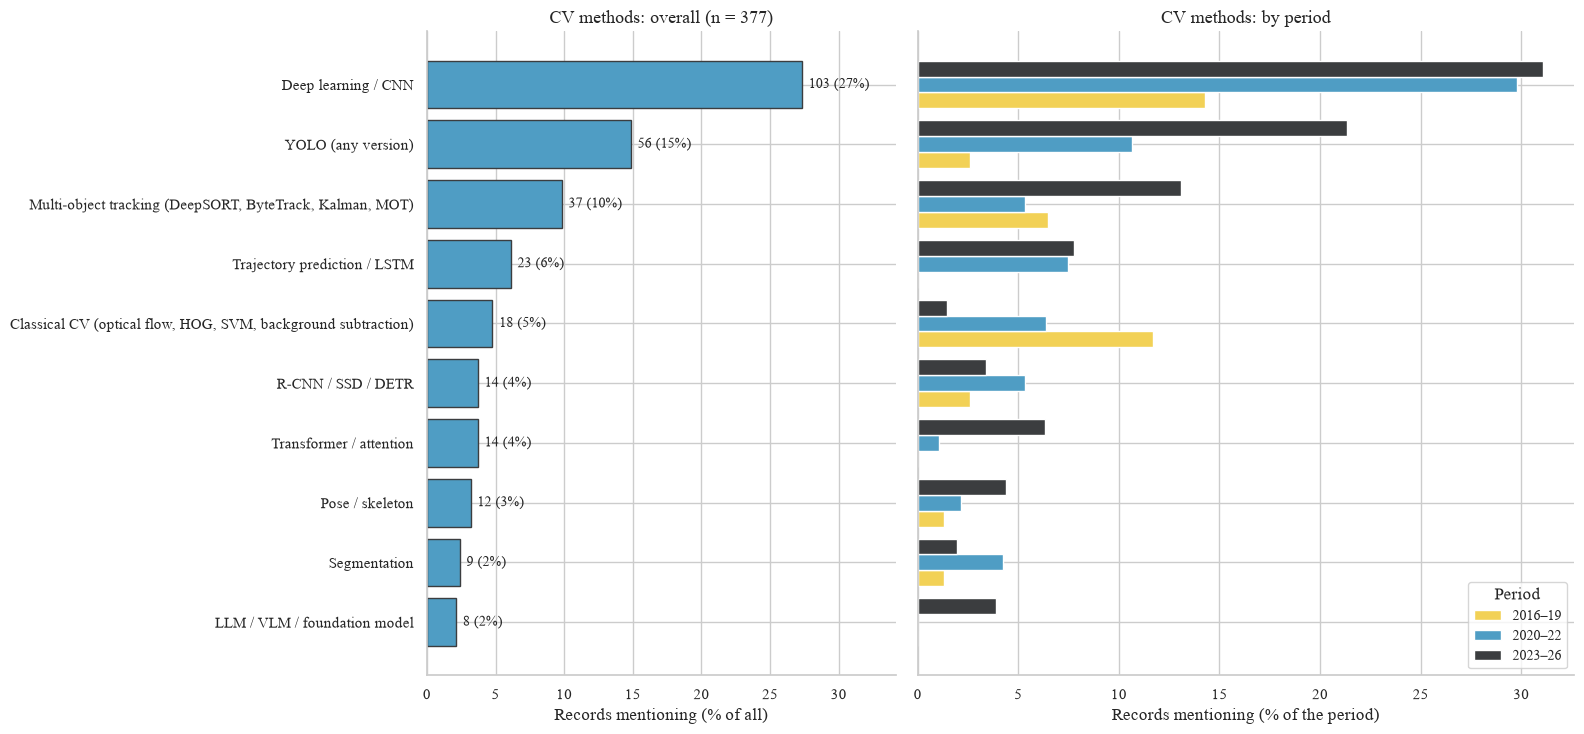

,records,% all,2016–19,2020–22,2023–26
category,,,,,
Deep learning / CNN,103,27.3,14.3,29.8,31.1
YOLO (any version),56,14.9,2.6,10.6,21.4
"Multi-object tracking (DeepSORT, ByteTrack, Kalman, MOT)",37,9.8,6.5,5.3,13.1
Trajectory prediction / LSTM,23,6.1,0.0,7.4,7.8
"Classical CV (optical flow, HOG, SVM, background subtraction)",18,4.8,11.7,6.4,1.5
Transformer / attention,14,3.7,0.0,1.1,6.3
R-CNN / SSD / DETR,14,3.7,2.6,5.3,3.4
Pose / skeleton,12,3.2,1.3,2.1,4.4
Segmentation,9,2.4,1.3,4.3,1.9


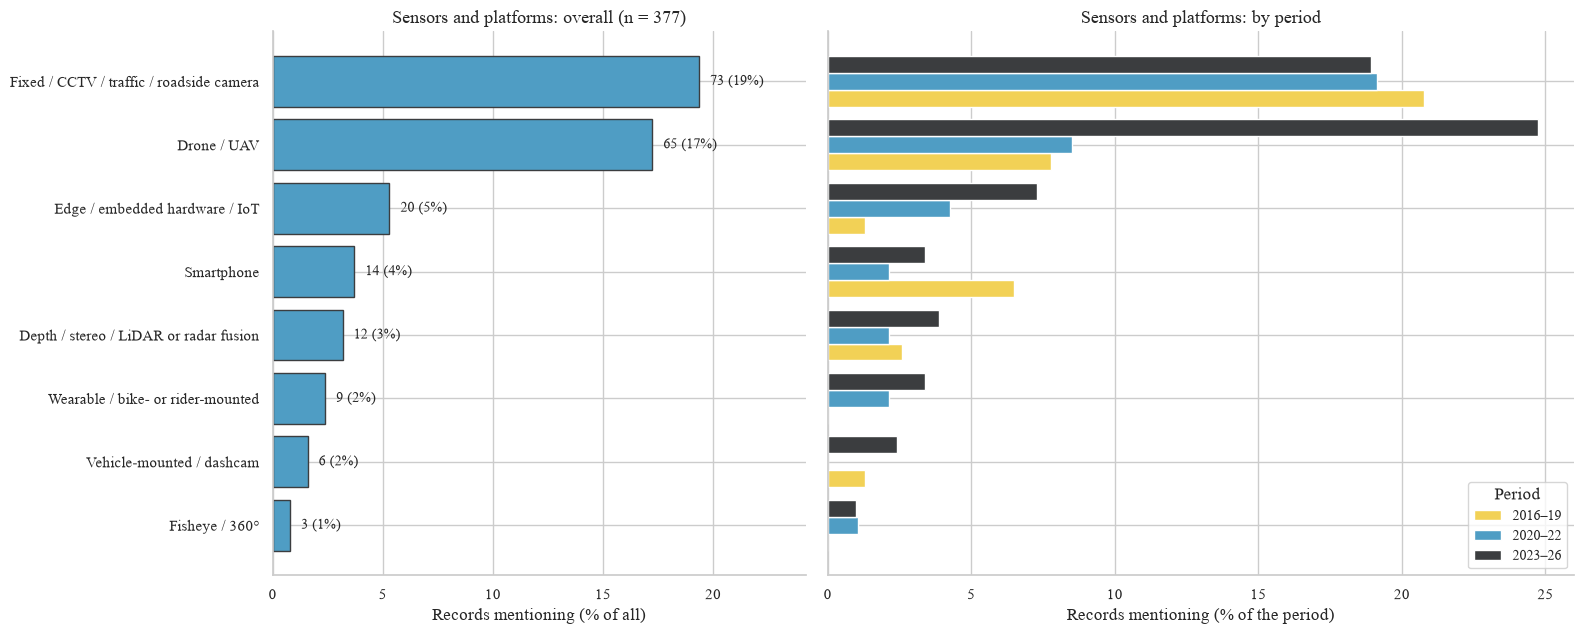

,records,% all,2016–19,2020–22,2023–26
category,,,,,
Fixed / CCTV / traffic / roadside camera,73,19.4,20.8,19.1,18.9
Drone / UAV,65,17.2,7.8,8.5,24.8
Edge / embedded hardware / IoT,20,5.3,1.3,4.3,7.3
Smartphone,14,3.7,6.5,2.1,3.4
Depth / stereo / LiDAR or radar fusion,12,3.2,2.6,2.1,3.9
Wearable / bike- or rider-mounted,9,2.4,0.0,2.1,3.4
Vehicle-mounted / dashcam,6,1.6,1.3,0.0,2.4
Fisheye / 360°,3,0.8,0.0,1.1,1.0


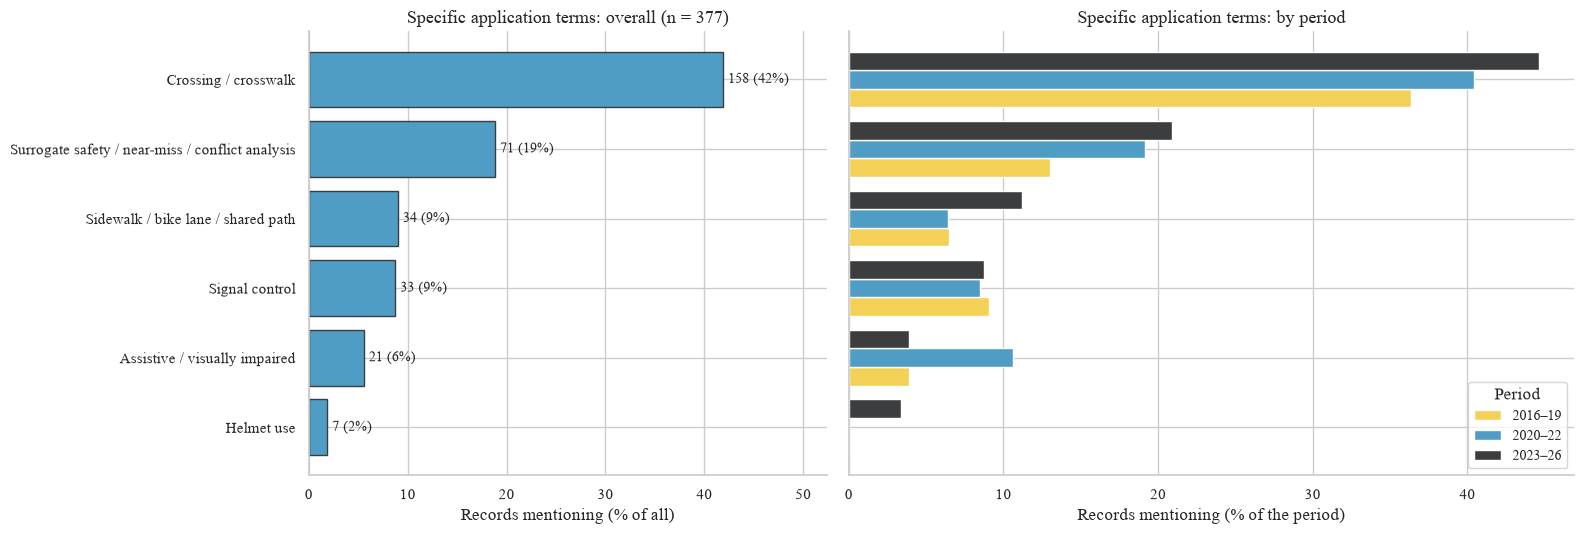

,records,% all,2016–19,2020–22,2023–26
category,,,,,
Crossing / crosswalk,158,41.9,36.4,40.4,44.7
Surrogate safety / near-miss / conflict analysis,71,18.8,13.0,19.1,20.9
Sidewalk / bike lane / shared path,34,9.0,6.5,6.4,11.2
Signal control,33,8.8,9.1,8.5,8.7
Assistive / visually impaired,21,5.6,3.9,10.6,3.9
Helmet use,7,1.9,0.0,0.0,3.4


In [5]:
rows = []
for group, terms in DICTIONARIES.items():
    for label, pattern in terms.items():
        m = df["_text"].str.contains(pattern, regex=True)
        df[f"_{group}__{label}"] = m
        row = {"group": group, "category": label, "records": int(m.sum()), "% all": m.mean() * 100}
        for p in PERIODS:
            in_p = df["period"] == p
            row[p] = m[in_p].mean() * 100 if in_p.any() else np.nan
        rows.append(row)
metrics = pd.DataFrame(rows)
metrics.round(1).to_csv(CONFIG["OUTPUT_CSV"], index=False)
print(f"Saved {CONFIG['OUTPUT_CSV']}")


def plot_group(group):
    sub = metrics[metrics["group"] == group].sort_values("% all")
    fig, axes = plt.subplots(1, 2, figsize=(16, 0.5 * len(sub) + 2.5), sharey=True,
                             gridspec_kw={"width_ratios": [1, 1.4]})

    bars = axes[0].barh(sub["category"], sub["% all"], color=MATTE_COLORS['blue'],
                        edgecolor=MATTE_COLORS['navy'], linewidth=1)
    for bar, n, s in zip(bars, sub["records"], sub["% all"]):
        axes[0].text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
                     f"{n} ({s:.0f}%)", va="center", fontsize=10)
    axes[0].set_xlabel("Records mentioning (% of all)")
    axes[0].set_title(f"{group}: overall (n = {len(df)})", fontsize=13)
    axes[0].set_xlim(0, sub["% all"].max() * 1.25)
    axes[0].spines[["top", "right"]].set_visible(False)

    y = np.arange(len(sub))
    h = 0.8 / len(PERIODS)
    for i, (p, color) in enumerate(zip(PERIODS, PERIOD_COLORS)):
        axes[1].barh(y + (i - (len(PERIODS) - 1) / 2) * h, sub[p], height=h, label=p, color=color)
    axes[1].set_xlabel("Records mentioning (% of the period)")
    axes[1].set_title(f"{group}: by period", fontsize=13)
    axes[1].legend(title="Period", loc="lower right", fontsize=10)
    axes[1].spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    plt.show()
    display(sub.drop(columns="group").sort_values("% all", ascending=False).round(1).set_index("category"))


for group in DICTIONARIES:
    plot_group(group)

### Coverage

Records that mention **no** category of a dictionary. For these the term approach cannot tell "the abstract does not report it" from "the abstract uses a term not in the dictionary"; this is the main reason the RQ results come from the LLM extraction.

In [6]:
for group in DICTIONARIES:
    cols = [c for c in df.columns if c.startswith(f"_{group}__")]
    none = ~df[cols].any(axis=1)
    print(f"{group:28s} no category mentioned: {int(none.sum()):3d} records ({none.mean():.0%})")

CV methods                   no category mentioned: 207 records (55%)
Sensors and platforms        no category mentioned: 204 records (54%)
Specific application terms   no category mentioned: 140 records (37%)


## Year-by-year trends

Raw counts per year for categories that change most between periods. Use them to locate when a shift starts; compare shares, not counts, across years, because the corpus grows every year (and 2026 is partial).

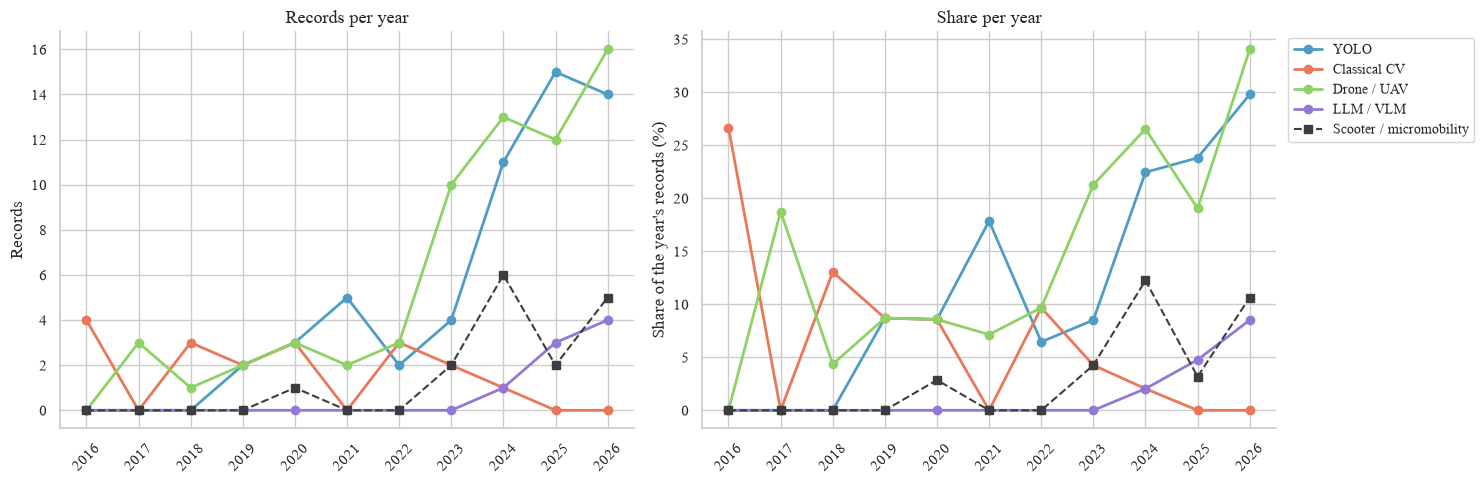

In [7]:
TREND_SERIES = {
    "YOLO": ("CV methods", "YOLO (any version)"),
    "Classical CV": ("CV methods", "Classical CV (optical flow, HOG, SVM, background subtraction)"),
    "Drone / UAV": ("Sensors and platforms", "Drone / UAV"),
    "LLM / VLM": ("CV methods", "LLM / VLM / foundation model"),
}
years = sorted(df["year"].dropna().astype(int).unique())
per_year_total = df.groupby("year").size().reindex(years)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
colors = [MATTE_COLORS[c] for c in ("blue", "red", "teal", "purple")]
for (name, (group, label)), color in zip(TREND_SERIES.items(), colors):
    counts = df.groupby("year")[f"_{group}__{label}"].sum().reindex(years, fill_value=0)
    axes[0].plot(years, counts, marker="o", label=name, color=color, linewidth=2)
    axes[1].plot(years, counts / per_year_total * 100, marker="o", label=name, color=color, linewidth=2)
    
micro = (df["road_user"] == "Scooter / micromobility (any)").groupby(df["year"]).sum().reindex(years, fill_value=0)
axes[0].plot(years, micro, marker="s", linestyle="--", label="Scooter / micromobility", color=MATTE_COLORS['navy'])
axes[1].plot(years, micro / per_year_total * 100, marker="s", linestyle="--",
             label="Scooter / micromobility", color=MATTE_COLORS['navy'])

axes[0].set_ylabel("Records"); axes[0].set_title("Records per year", fontsize=13)
axes[1].set_ylabel("Share of the year's records (%)"); axes[1].set_title("Share per year", fontsize=13)
for ax in axes:
    ax.set_xticks(years)
    ax.tick_params(axis="x", rotation=45)
    ax.spines[["top", "right"]].set_visible(False)
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=10)
plt.tight_layout()
plt.show()

## Cross-tabulations

Which sensors go with which methods, and which sensors serve which road users. Cells show the number of records that mention both; empty cells are candidate gaps.

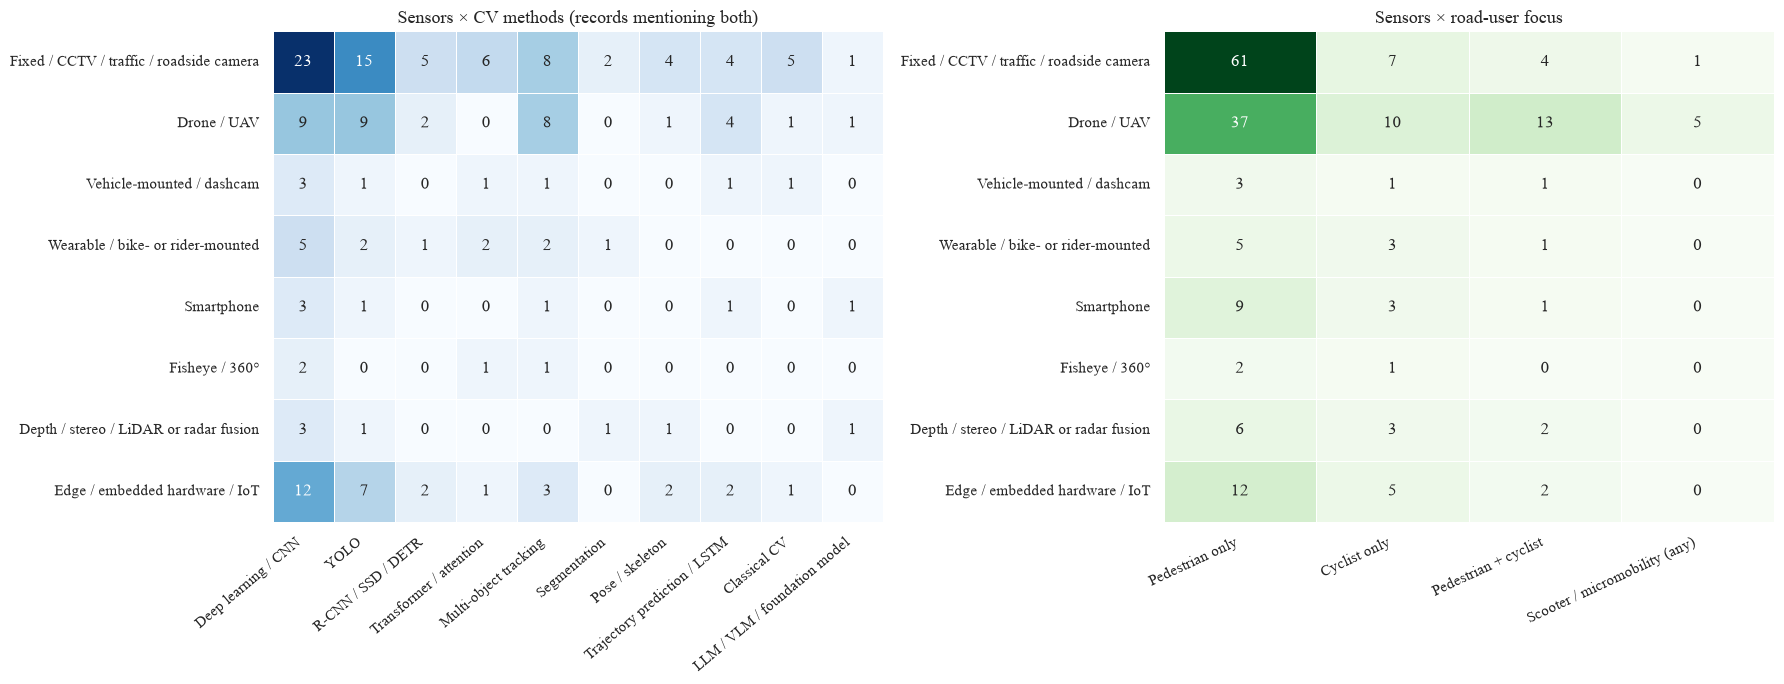

In [8]:
def short(label):
    """Drop the parenthesised examples so heatmap labels stay readable."""
    return re.sub(r"\s*\(.*?\)", "", label)


def cross(group_a, group_b):
    cols_a = [c for c in df.columns if c.startswith(f"_{group_a}__")]
    cols_b = [c for c in df.columns if c.startswith(f"_{group_b}__")]
    table = pd.DataFrame({short(cb.split("__", 1)[1]): [int((df[ca] & df[cb]).sum()) for ca in cols_a]
                          for cb in cols_b}, index=[short(ca.split("__", 1)[1]) for ca in cols_a])
    return table


fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sensor_method = cross("Sensors and platforms", "CV methods")
sns.heatmap(sensor_method, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0], linewidths=0.5)
axes[0].set_title("Sensors × CV methods (records mentioning both)", fontsize=13)
plt.setp(axes[0].get_xticklabels(), rotation=40, ha="right")

sensor_cols = [c for c in df.columns if c.startswith("_Sensors and platforms__")]
sensor_user = pd.DataFrame({ru: [int((df[c] & (df["road_user"] == ru)).sum()) for c in sensor_cols]
                            for ru in ROAD_USER_ORDER if ru != "Unspecified"},
                           index=[short(c.split("__", 1)[1]) for c in sensor_cols])
sns.heatmap(sensor_user, annot=True, fmt="d", cmap="Greens", cbar=False, ax=axes[1], linewidths=0.5)
axes[1].set_title("Sensors × road-user focus", fontsize=13)
plt.setp(axes[1].get_xticklabels(), rotation=25, ha="right")

plt.tight_layout()
plt.show()

## Audit

Matched term and the text around it, for a random sample of records in a category, to estimate precision by reading ("is this what the category means, or a passing mention?"). Set `AUDIT_CATEGORY = None` to sample every category of `AUDIT_GROUP`. Refine the pattern in the dictionary cell if you see false matches, and re-run.

In [9]:
AUDIT_GROUP = "Sensors and platforms"
AUDIT_CATEGORY = None      # e.g. "Drone / UAV"; None = every category of the group
AUDIT_N = 8
CONTEXT_CHARS = 90

categories = [AUDIT_CATEGORY] if AUDIT_CATEGORY else list(DICTIONARIES[AUDIT_GROUP])
for category in categories:
    pattern = DICTIONARIES[AUDIT_GROUP][category]
    hits = df[df[f"_{AUDIT_GROUP}__{category}"]]
    print(f"\n=== {category}: {len(hits)} records (sample of {min(AUDIT_N, len(hits))}) ===")
    for _, r in hits.sample(min(AUDIT_N, len(hits)), random_state=0).iterrows():
        m = re.search(pattern, r["_text"])
        start, end = max(0, m.start() - CONTEXT_CHARS), m.end() + CONTEXT_CHARS
        print(f"  [{int(r['year'])}] [{m.group(0)}] ...{r['_text'][start:end]}...")


=== Fixed / CCTV / traffic / roadside camera: 73 records (sample of 8) ===
  [2021] [surveillance] ...tive e-bikes. finally, the model was calibrated with trajectory data collected from video surveillance, and two types of numerical simulations were carried out. the experiment results verified...
  [2020] [surveillance] ...tand road user behavior using either purely spatial trajectory data, or videos from fixed surveillance camera through tracking or predicting their paths. however, these data only cover limited...
  [2025] [surveillance] ...ue to severe occlusion and repeated movement, accurate pedestrian route counting in video surveillance remains challenging in high-density scenes. to address this issue, this paper proposes an...
  [2022] [cctv] ...s paper uses pose estimation (keypoint detection) to generate pedestrians' variables from cctv videos. four machine learning models are used to predict pedestrians' crossing intention ...
  [2024] [surveillance] ...a is crucial for rese